Dataset Loaded Successfully


,rownames,Gunnel,Time,Fromlow,Slope,Rw,Amphiso,Subst,Pool,Water,Cobble
0,1,0,786,190,10,0.1,0,3,0,0,0
1,2,0,794,182,10,0.0,0,3,0,0,0
2,3,0,798,178,20,0.0,0,1,0,0,0
3,4,0,800,176,70,0.3,0,1,0,1,0
4,5,0,804,172,40,0.3,0,1,0,1,0


,Statistic,Value
0,Mean,9.503769
1,Median,0.000000
2,Minimum,0.000000
3,Maximum,90.000000
4,Range,90.000000
5,Variance,252.487729
6,Standard Deviation,15.889862
7,IQR,10.000000
8,Skewness,2.952982
9,Kurtosis,10.221232


,Frequency,Relative_Frequency
Water_Category,,
1,810,0.508794
0,782,0.491206


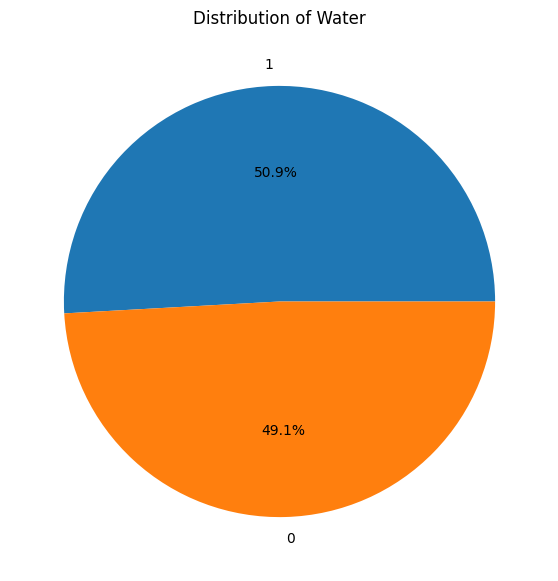

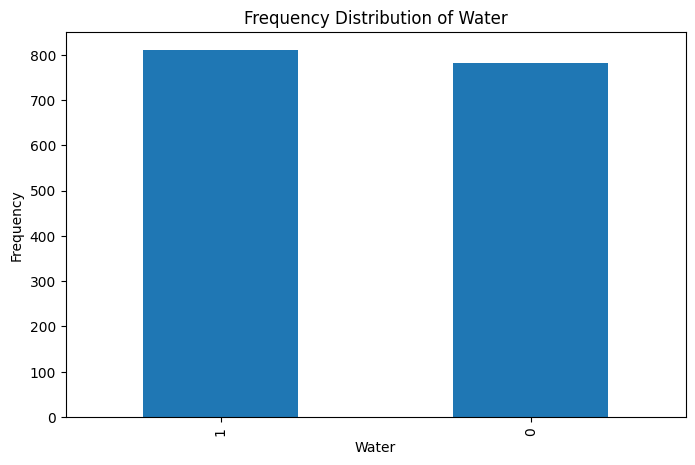

Slope Frequency Distribution:


Slope
(-0.09, 18.0]    1307
(18.0, 36.0]      193
(36.0, 54.0]       46
(54.0, 72.0]       14
(72.0, 90.0]       32
Name: count, dtype: int64

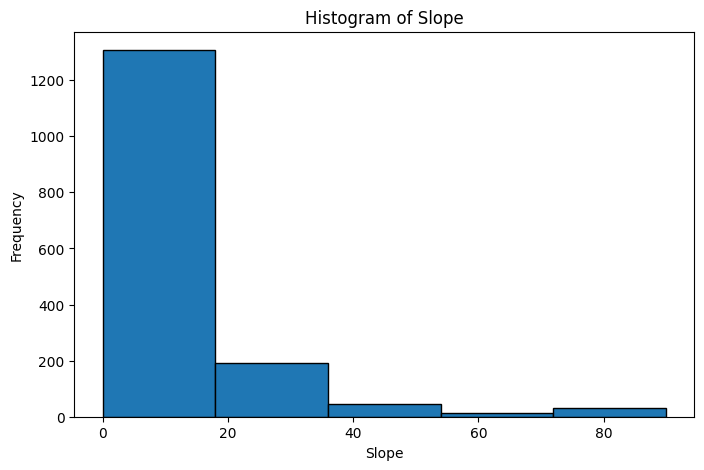

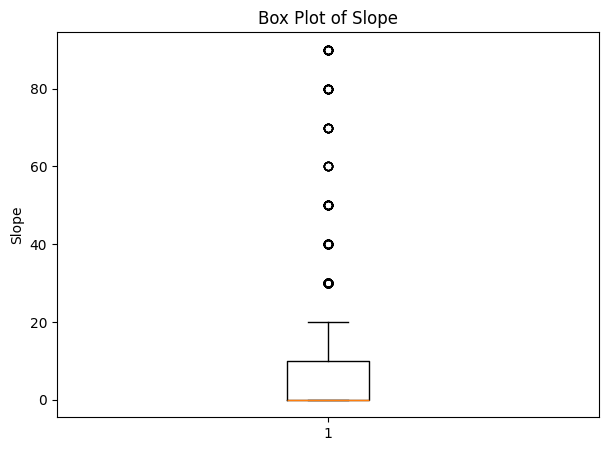

Contingency Table:


Cobble_Category,0,1
Water_Category,,
0,659,123
1,629,181


Row Percentages:


Cobble_Category,0,1
Water_Category,,
0,84.271100,15.728900
1,77.654321,22.345679


Column Percentages:


Cobble_Category,0,1
Water_Category,,
0,51.164596,40.460526
1,48.835404,59.539474


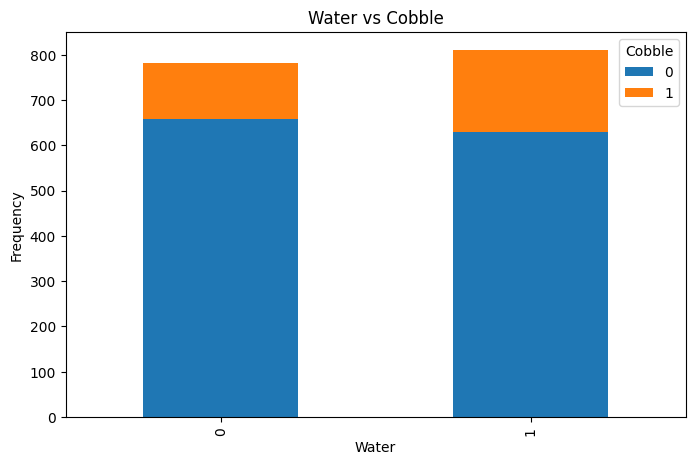

,mean,median,std
Water_Category,,,
0,10.562660,0.0,18.046477
1,8.481481,0.0,13.416971


C:\Users\aksha\AppData\Local\Temp\ipykernel_20724\3268771526.py:298: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


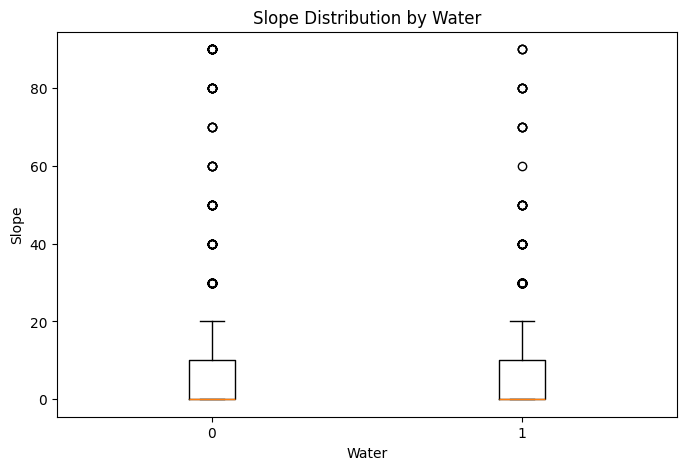

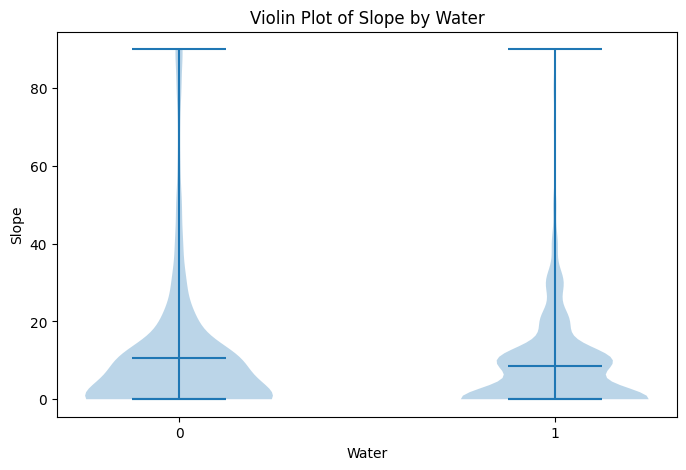

Pearson Correlation: 0.019566473129542624
Spearman Correlation: 0.11201543626423055


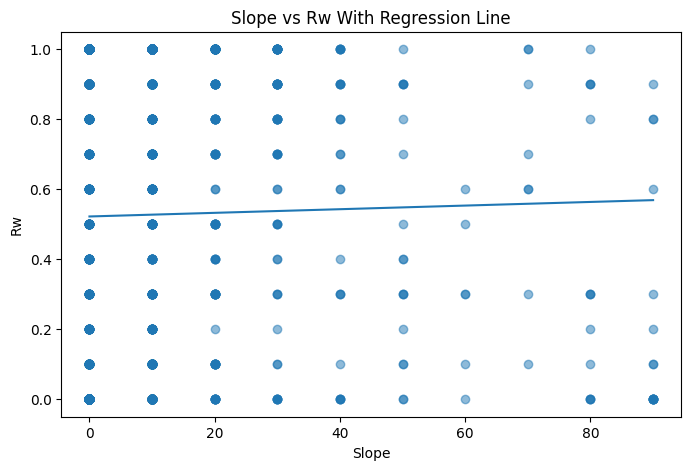

mean        std
Water_Category Cobble_Category                      
0              0                11.122914  19.208069
               1                 7.560976   9.174221
1              0                 9.777424  14.605690
               1                 3.977901   6.207483

C:\Users\aksha\AppData\Local\Temp\ipykernel_20724\3268771526.py:438: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


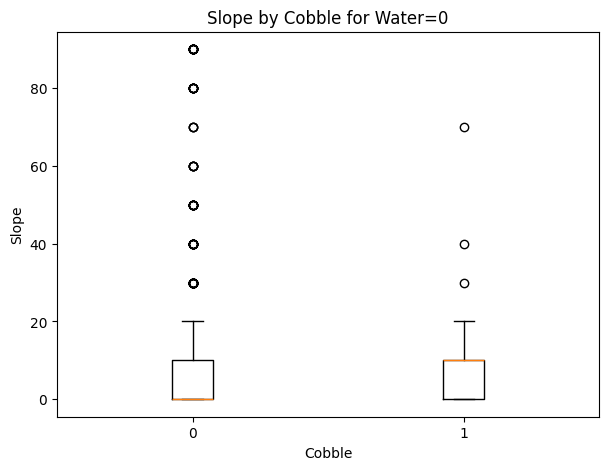

C:\Users\aksha\AppData\Local\Temp\ipykernel_20724\3268771526.py:438: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


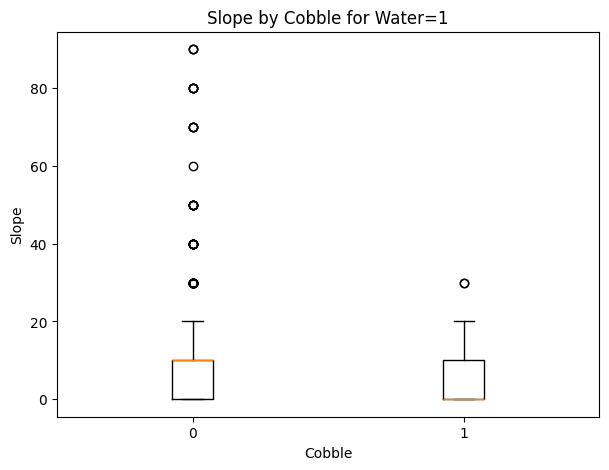

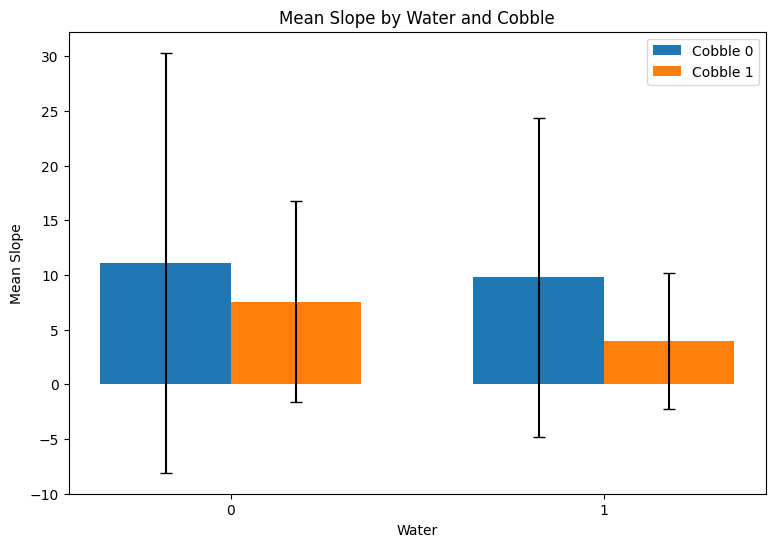

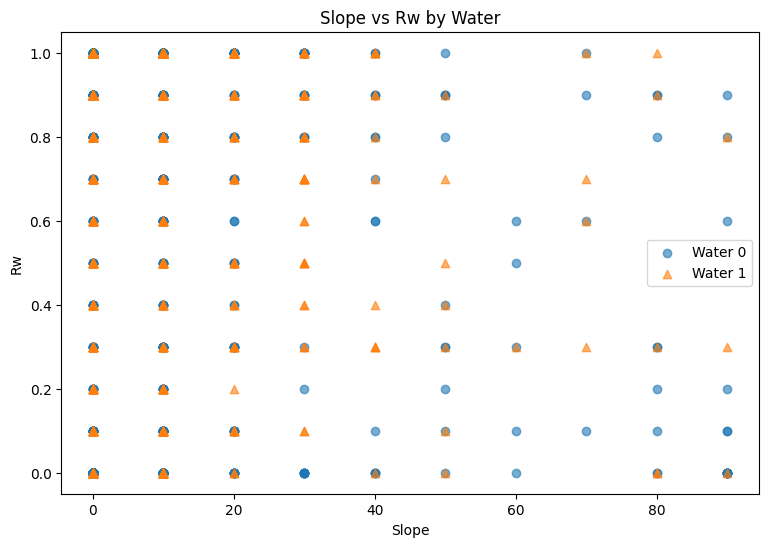

Correlation Matrix for Water = 0


,Slope,Rw
Slope,1.000000,0.104398
Rw,0.104398,1.000000


Correlation Matrix for Water = 1


,Slope,Rw
Slope,1.000000,-0.042134
Rw,-0.042134,1.000000


Correlation Matrix:


,Time,Fromlow,Slope,Rw,Amphiso
Time,1.000000,0.215593,-0.076922,0.047812,-0.094952
Fromlow,0.215593,1.000000,0.090586,-0.348612,-0.118838
Slope,-0.076922,0.090586,1.000000,0.019566,-0.078461
Rw,0.047812,-0.348612,0.019566,1.000000,0.230164
Amphiso,-0.094952,-0.118838,-0.078461,0.230164,1.000000


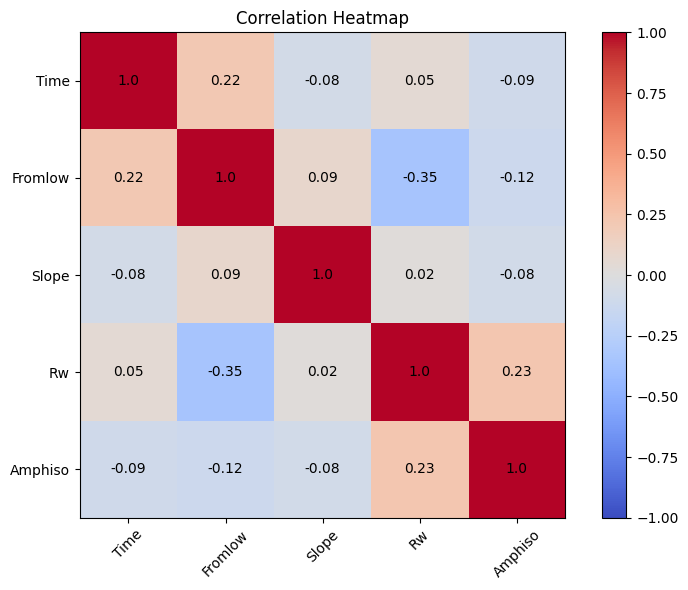

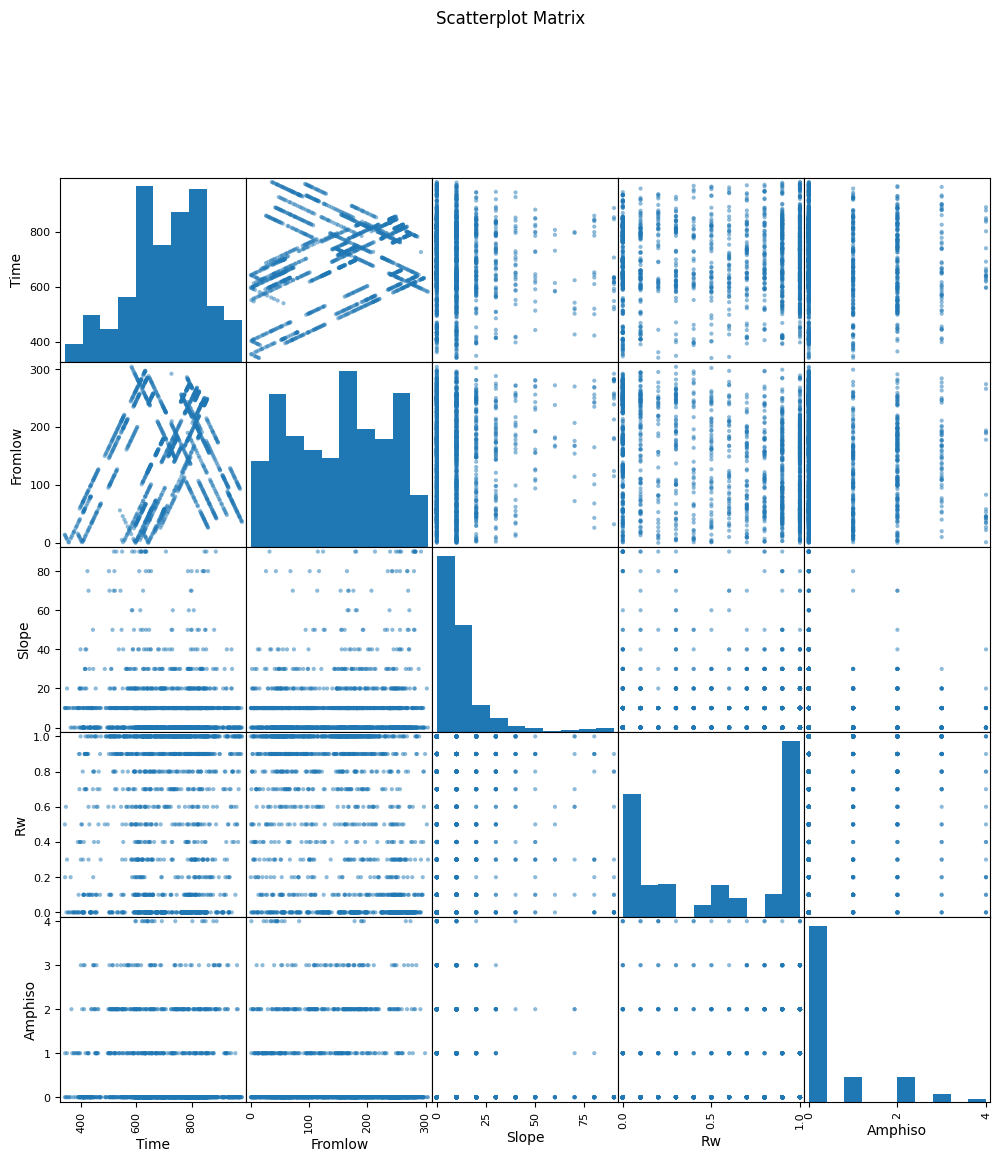

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import skew
from scipy.stats import kurtosis
from pandas.plotting import scatter_matrix

# ASSESSMENT 7
# 1D, 2D AND ND ANALYSIS

# 1. Load Dataset
url = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/Gunnels.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully")

display(df.head())

# Create categorical versions
df["Water_Category"] = (
    df["Water"].astype(str)
)

df["Cobble_Category"] = (
    df["Cobble"].astype(str)
)

df["Pool_Category"] = (
    df["Pool"].astype(str)
)

# 2. Summary Statistics
num_col = "Slope"

mean_value = df[
    num_col
].mean()

median_value = df[
    num_col
].median()

minimum = df[
    num_col
].min()

maximum = df[
    num_col
].max()

data_range = (
    maximum - minimum
)

variance = df[
    num_col
].var()

std_deviation = df[
    num_col
].std()

Q1 = df[
    num_col
].quantile(0.25)

Q3 = df[
    num_col
].quantile(0.75)

IQR = Q3 - Q1

skewness = skew(
    df[num_col].dropna()
)

kurtosis_value = kurtosis(
    df[num_col].dropna()
)

# 3. Store Statistics in DataFrame
statistics = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "Range",
        "Variance",
        "Standard Deviation",
        "IQR",
        "Skewness",
        "Kurtosis"
    ],

    "Value": [
        mean_value,
        median_value,
        minimum,
        maximum,
        data_range,
        variance,
        std_deviation,
        IQR,
        skewness,
        kurtosis_value
    ]
})

display(statistics)

# 4. Frequency and Relative Frequency Distribution
cat_col = "Water_Category"

frequency = df[
    cat_col
].value_counts()

relative_frequency = df[
    cat_col
].value_counts(
    normalize=True
)

frequency_table = pd.DataFrame({
    "Frequency": frequency,
    "Relative_Frequency": relative_frequency
})

display(frequency_table)

# Pie Chart
plt.figure(figsize=(7, 7))

frequency.plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title(
    "Distribution of Water"
)

plt.ylabel("")

plt.show()

# Bar Plot
plt.figure(figsize=(8, 5))

frequency.plot(
    kind="bar"
)

plt.title(
    "Frequency Distribution of Water"
)

plt.xlabel("Water")
plt.ylabel("Frequency")

plt.show()

# 5. Frequency Distribution With Bin Intervals
bins = pd.cut(
    df["Slope"],
    bins=5
)

bin_frequency = bins.value_counts(
    sort=False
)

print(
    "Slope Frequency Distribution:"
)

display(bin_frequency)

# Histogram
plt.figure(figsize=(8, 5))

plt.hist(
    df["Slope"],
    bins=5,
    edgecolor="black"
)

plt.title(
    "Histogram of Slope"
)

plt.xlabel("Slope")
plt.ylabel("Frequency")

plt.show()

# Box Plot
plt.figure(figsize=(7, 5))

plt.boxplot(
    df["Slope"].dropna()
)

plt.title(
    "Box Plot of Slope"
)

plt.ylabel("Slope")

plt.show()

# 6. Two Categorical Variables
contingency = pd.crosstab(
    df["Water_Category"],
    df["Cobble_Category"]
)

print(
    "Contingency Table:"
)

display(contingency)

row_percentage = (
    contingency.div(
        contingency.sum(axis=1),
        axis=0
    ) * 100
)

print(
    "Row Percentages:"
)

display(row_percentage)

column_percentage = (
    contingency.div(
        contingency.sum(axis=0),
        axis=1
    ) * 100
)

print(
    "Column Percentages:"
)

display(column_percentage)

# 7. Stacked Bar Plot
contingency.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title(
    "Water vs Cobble"
)

plt.xlabel("Water")
plt.ylabel("Frequency")

plt.legend(
    title="Cobble"
)

plt.show()

# 8. Grouped Mean, Median and Standard Deviation
group_statistics = df.groupby(
    "Water_Category"
)["Slope"].agg([
    "mean",
    "median",
    "std"
])

display(group_statistics)

# 9. Side-by-Side Box Plots
water_groups = sorted(
    df["Water_Category"].unique()
)

box_data = [
    df[
        df["Water_Category"] == group
    ]["Slope"].dropna()
    for group in water_groups
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    box_data,
    labels=water_groups
)

plt.title(
    "Slope Distribution by Water"
)

plt.xlabel("Water")
plt.ylabel("Slope")

plt.show()

# Violin Plot
plt.figure(figsize=(8, 5))

plt.violinplot(
    box_data,
    showmeans=True,
    showmedians=True
)

plt.xticks(
    range(
        1,
        len(water_groups) + 1
    ),
    water_groups
)

plt.title(
    "Violin Plot of Slope by Water"
)

plt.xlabel("Water")
plt.ylabel("Slope")

plt.show()

# 10. Pearson and Spearman Correlation
x = "Slope"
y = "Rw"

pearson = df[
    [x, y]
].corr(
    method="pearson"
).iloc[0, 1]

spearman = df[
    [x, y]
].corr(
    method="spearman"
).iloc[0, 1]

print(
    "Pearson Correlation:",
    pearson
)

print(
    "Spearman Correlation:",
    spearman
)

# Linear Regression
coefficients = np.polyfit(
    df[x],
    df[y],
    1
)

regression_line = np.poly1d(
    coefficients
)

sorted_x = np.sort(
    df[x]
)

plt.figure(figsize=(8, 5))

plt.scatter(
    df[x],
    df[y],
    alpha=0.5
)

plt.plot(
    sorted_x,
    regression_line(sorted_x)
)

plt.title(
    "Slope vs Rw With Regression Line"
)

plt.xlabel("Slope")
plt.ylabel("Rw")

plt.show()

# 11. Two Categorical Features and One Numerical Feature
summary_3d = df.groupby(
    [
        "Water_Category",
        "Cobble_Category"
    ]
)["Slope"].agg([
    "mean",
    "std"
])

display(summary_3d)

# Faceted Box Plot Equivalent
for water in sorted(
    df["Water_Category"].unique()
):

    subset = df[
        df["Water_Category"] == water
    ]

    categories = sorted(
        subset[
            "Cobble_Category"
        ].unique()
    )

    values = [
        subset[
            subset["Cobble_Category"] == c
        ]["Slope"].dropna()
        for c in categories
    ]

    plt.figure(figsize=(7, 5))

    plt.boxplot(
        values,
        labels=categories
    )

    plt.title(
        f"Slope by Cobble for Water={water}"
    )

    plt.xlabel("Cobble")
    plt.ylabel("Slope")

    plt.show()

# Grouped Bar Chart With Error Bars
summary_reset = (
    summary_3d
    .reset_index()
)

water_values = sorted(
    summary_reset[
        "Water_Category"
    ].unique()
)

cobble_values = sorted(
    summary_reset[
        "Cobble_Category"
    ].unique()
)

x_positions = np.arange(
    len(water_values)
)

width = 0.35

plt.figure(figsize=(9, 6))

for i, cobble in enumerate(
    cobble_values
):

    temp = summary_reset[
        summary_reset[
            "Cobble_Category"
        ] == cobble
    ]

    means = []

    errors = []

    for water in water_values:

        row = temp[
            temp[
                "Water_Category"
            ] == water
        ]

        if len(row) > 0:

            means.append(
                row["mean"].iloc[0]
            )

            errors.append(
                row["std"].iloc[0]
            )

        else:

            means.append(0)
            errors.append(0)

    plt.bar(
        x_positions
        + i * width,
        means,
        width,
        yerr=errors,
        capsize=4,
        label=f"Cobble {cobble}"
    )

plt.xticks(
    x_positions
    + width / 2,
    water_values
)

plt.xlabel("Water")
plt.ylabel("Mean Slope")

plt.title(
    "Mean Slope by Water and Cobble"
)

plt.legend()

plt.show()

# 12. One Categorical + Two Numerical Variables
plt.figure(figsize=(9, 6))

markers = [
    "o",
    "^",
    "s",
    "D"
]

for i, category in enumerate(
    sorted(
        df[
            "Water_Category"
        ].unique()
    )
):

    subset = df[
        df[
            "Water_Category"
        ] == category
    ]

    plt.scatter(
        subset["Slope"],
        subset["Rw"],
        marker=markers[
            i % len(markers)
        ],
        alpha=0.6,
        label=f"Water {category}"
    )

plt.title(
    "Slope vs Rw by Water"
)

plt.xlabel("Slope")
plt.ylabel("Rw")

plt.legend()

plt.show()

# Correlation for Each Category
for category in sorted(
    df[
        "Water_Category"
    ].unique()
):

    subset = df[
        df[
            "Water_Category"
        ] == category
    ]

    print(
        f"Correlation Matrix for Water = {category}"
    )

    display(
        subset[
            ["Slope", "Rw"]
        ].corr()
    )

# 13. Full Correlation Matrix
features = [
    "Time",
    "Fromlow",
    "Slope",
    "Rw",
    "Amphiso"
]

correlation_matrix = df[
    features
].corr()

print(
    "Correlation Matrix:"
)

display(
    correlation_matrix
)

# Heatmap
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar()

plt.xticks(
    range(
        len(features)
    ),
    features,
    rotation=45
)

plt.yticks(
    range(
        len(features)
    ),
    features
)

for i in range(
    len(features)
):

    for j in range(
        len(features)
    ):

        plt.text(
            j,
            i,
            round(
                correlation_matrix.iloc[
                    i, j
                ],
                2
            ),
            ha="center",
            va="center"
        )

plt.title(
    "Correlation Heatmap"
)

plt.tight_layout()

plt.show()

# 14. Pairs Plot / Scatterplot Matrix
scatter_matrix(
    df[features],
    figsize=(12, 12),
    diagonal="hist"
)

plt.suptitle(
    "Scatterplot Matrix",
    y=1.02
)

plt.show()